# Rozdzielczość obrazu. Interpolacja.

## Cel zajęć:

* zapoznanie z pojęciem rozdzielczości przestrzennej (rozmiaru obrazu),
* metody interpolacji najbliższego sąsiada oraz dwuliniowa,
* zapoznanie z pojęciem rozdzielczości dpi (ang. dots per inch),
* zapoznanie z pojęciem rozdzielczości  poziomów jasności (dla obrazów w skali szarości),
* zadanie domowe: interpolacja dwusześcienna.

## Rodzielczość przestrzenna

Dyskretna reprezentacja obrazu to zwykle macierz dwu (N x M - obraz w skali szarości) lub trójwymiarowa (N x M x 3 - obraz kolorowy).
Przez rozdzielczość przestrzenną rozumie się liczbę pikseli z których składa się obraz.
Przykładowo rozdzielczość VGA to  640 x 480, FullHD to 1920 x 1080, a UltraHD (4K) to 3840 x 2160.
Rozdzielczość obrazu można modyfikować (zwiększać/zmniejszać), co nazywa się skalowaniem obrazu.
Warto wiedzieć, że zwiększenie rozdzielczości obrazu nie zwiększa ilości informacji, a jedynie liczbę pikseli (w sensie "lepiej nie będzie").
Ponadto skalowanie zawsze wprowadza pewne zniekształcenia, nawet przy zmniejszaniu rozmiaru.

W ramach niniejszego ćwiczenia zapoznamy się z metodami interpolacji, które są podstawą takich operacji jak: przybliżanie (zoom), zmiana rozdzielczości, rotacja obrazu, czy też korekcje geometryczne.
Jako przykład posłuży nam zmiana rozdzielczości, czyli inaczej mówiąc przepróbkowanie obrazu.
Dla przypomnienia - interpolacja to wykorzystanie znanych danych (wartości dla tzw. punktów węzłowych) do określania wartości w nieznanych lokalizacjach.

Zacznijmy od prostego przykładu.
Mamy obraz o rozdzielczości 500 x 500 pikseli, a chcemy go powiększyć do 750 x 750 pikseli - tj. o współczynnik 1,5.
Wyobraźmy sobie zatem, że dysponujemy siatką 750 x 750 o takim samym "rozmiarze" pojedynczego piksela jak obraz oryginalny.
Następnie siatkę tą ,,ścieśniamy'', tak aby miała rozmiar 500 x 500.
W rezultacie otrzymana siatka będzie miała mniejszy rozmiar pojedynczego piksela niż obraz oryginalny.
Schematycznie przedstawiono to na poniższym rysunku.

![Ilustracja interpolacji](https://raw.githubusercontent.com/vision-agh/poc_sw/master/05_Resolution/img/interEx57.png)


Pokazuje on przykład interpolacji: a) obraz 5x5, b) oraz 7x7, c) obraz 7x7 zmiejszony do 5x5.


Chcemy teraz poszczególnym elementom nowej siatki przyporządkować piksele z obrazu wejściowego.
Jedną z możliwości jest poszukanie "najbliższego" piksela w oryginalnym obrazie i wzięcie jego wartości.
Przykład takiego postępowania zaprezentowano na  poniższym rysunku.

![Ilustracja najbliższego sąsiada](https://raw.githubusercontent.com/vision-agh/poc_sw/master/05_Resolution/img/inteNNEx.png)

Kilka słów wyjasnienia.
Kolorem ciemnoszarym oznaczono siatkę 5x5, a czarnym 7x7 (już po przeskalowaniu).
Nasze zadanie sprowadza się do znalezienia dla każdej kropki czarnej (umowny środek piksela), najbliżej leżącej kropki szarej - oznaczono to dla pierwszych trzech wierzszy obrazu liniami.

Po zrealizowaniu powyższego kroku dla całego obrazu wykonujemy "rozciągniecie" do rozdzielczości 750 x 750.
W ten sposób uzyskujemy finalny efekt zmiany rozdzielczości.

Ważną sprawą jest również to, że iterujemy po pikselach nowego obrazu, poszukując najbliższych sąsiadów w starym obrazie. Dzięki temu każdy piksel nowego obrazu będzie miał jakąś wartość (może to być także ten sam sąsiad). Gdybyśmy iterowali odwrotnie, tzn. po pikselach starego obrazu, wówczas na nowym obrazie mogłyby powstać "dziury".

Inna kwestia to występujące w procesie skalowania zaokrąglenia. Aby uniknąć wizualnego "przesunięcia" obrazu, trzeba zastosować wzór:
\begin{equation}
x_{src} = (x_{dst} + 0.5)/scale - 0.5
\end{equation}
Należy też pamiętać o specyfice funkcji round() w Pythonie, która liczby z końcówką .5 zaokrągla do najbliższej liczby parzystej.

## Interpolacja metodą najbliższego sąsiada

Takie postępowanie określa się mianem **interpolacji metodą najbliższego sąsiada** (ang. *nearest neighbour interpolation*).
W ramach pierwszego etapu ćwiczenia zaimplementujemy to podejście.

1. Ładujemy potrzebne biblioteki, pobieramy obrazy z repozytorium, wczytujemy jeden z obrazów testowych (*parrot.bmp*) i wyświetlamy go:

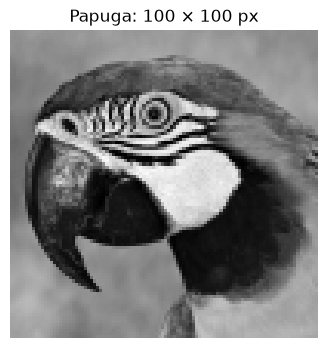

In [ ]:
import cv2
import requests
import numpy as np
from pathlib import Path
from matplotlib import pyplot as plt

folder = Path("lab5") if Path("lab5").is_dir() else Path(".")
url = "https://raw.githubusercontent.com/vision-agh/poc_sw/master/05_Resolution/"
for name in ["parrot.bmp", "clock.bmp", "chessboard.bmp", "firetruck.jpg", "lena.bmp"]:
    path = folder / name
    if not path.exists():
        response = requests.get(url + name, timeout=30)
        response.raise_for_status()
        path.write_bytes(response.content)

parrot = cv2.imread(str(folder / "parrot.bmp"), cv2.IMREAD_GRAYSCALE)
clock = cv2.imread(str(folder / "clock.bmp"), cv2.IMREAD_GRAYSCALE)
chessboard = cv2.imread(str(folder / "chessboard.bmp"), cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(4, 4))
plt.imshow(parrot, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title(f"Papuga: {parrot.shape[1]} × {parrot.shape[0]} px")
plt.axis("off")
plt.show()

2. Definiujemy funkcję do interpolacji metodą najbliższego sąsiada.

Jako argumenty wejściowe powinna ona przyjąć obraz oraz współczynniki skalowania w pionie i poziomie.
Wyjściem powinien być natomiast obraz w nowej rozdzielczości.
Wewnątrz należy:

* odczytać wymiary obrazka wejściowego,
* wyliczyć wymiary obrazka wyjściowego (tj. wymnożyć wymiary wejściowe przez skalę i zaokrąglić do liczb całkowitych),
* utworzyć nowy obraz o ww. rozmiarze,
* w pętli po nowym obrazie, dla każdego piksela, wykorzystując współczynniki skalowania, odnaleźć najbliższego sąsiada.




In [ ]:
def nearest_neighbor(image, h_scale, w_scale):
    height, width = image.shape
    new_height = max(1, round(height * h_scale))
    new_width = max(1, round(width * w_scale))

    result = np.zeros((new_height, new_width), dtype=image.dtype)

    sy = new_height / height # rzeczywiste skale
    sx = new_width / width
    
    for y in range(new_height):
        for x in range(new_width):
            src_y = (y + 0.5) / sy - 0.5
            src_x = (x + 0.5) / sx - 0.5

            # najbliższy piksel. +0.5 i floor zamiast round do parzystej
            yy = int(np.floor(src_y + 0.5))
            xx = int(np.floor(src_x + 0.5))

            yy = min(max(yy, 0), height - 1)
            xx = min(max(xx, 0), width - 1)
            
            result[y, x] = image[yy, xx]
    
    return result

3. Testujemy stworzoną funkcję:
    * dla skali 1.5, 1.5 i obrazka *parrot*,
    * dla 2.5, 2.5 - tu może okazać się, że do kodu trzeba dopisać zabezpieczenie przed wyjściem poza zakres,
    * dla niejednakowych skal np. 1.5 i 2.5,
    * dla skal mniejszych od 1,
    * dla niesymetrycznego obrazka *clock*,
    * dla obrazka z szachownicą *chessboard*.

Uwaga: proszę dla powyższych przypadków przygotować osobne sekcje kodu - tak, aby wyświetlały się wszystkie rozważane przypadki.

Wykonana metoda jest bardzo prosta i szybka, ale wprowadza pewne niepożądane artefakty, w szczególnie źle odwzorowane są linie proste.
Z drugiej strony sprawdza się w pewnych nietypowych przypadkach.
Zostanie to zademonstrowane w dalszej części ćwiczenia.

In [3]:
def show_pair(original, result, title):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, image, label in zip(axes, [original, result], ["Oryginał", "Wynik"]):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"{label}: {image.shape[1]} × {image.shape[0]} px")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

#### Papuga: powiększenie 1.5 × 1.5

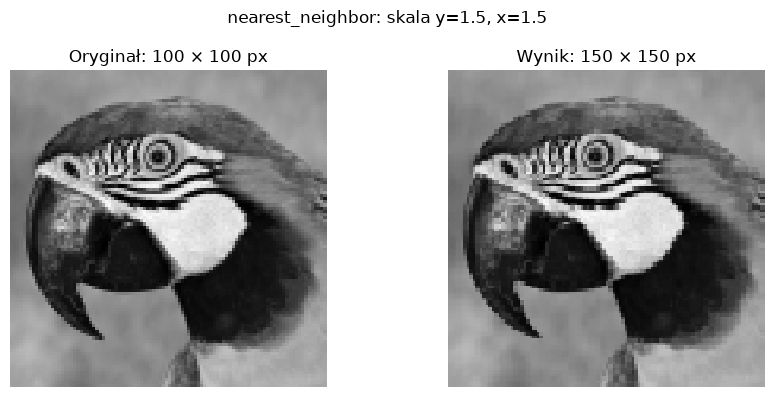

In [4]:
result = nearest_neighbor(parrot, 1.5, 1.5)
show_pair(parrot, result, "nearest_neighbor: skala y=1.5, x=1.5")

#### Papuga: powiększenie 2.5 × 2.5

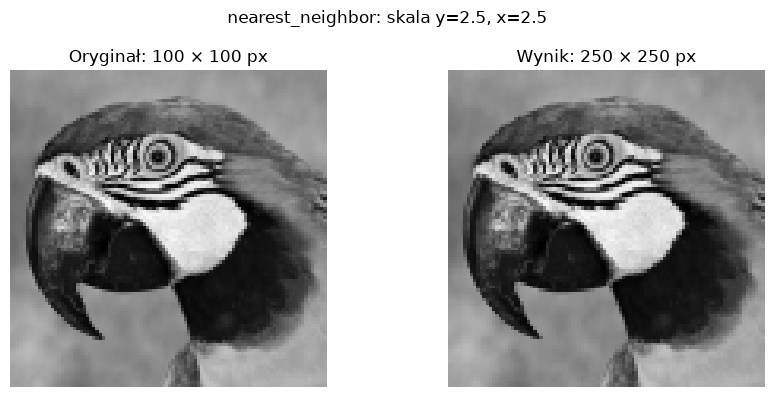

In [5]:
result = nearest_neighbor(parrot, 2.5, 2.5)
show_pair(parrot, result, "nearest_neighbor: skala y=2.5, x=2.5")

#### Papuga: różne skale w pionie i poziomie

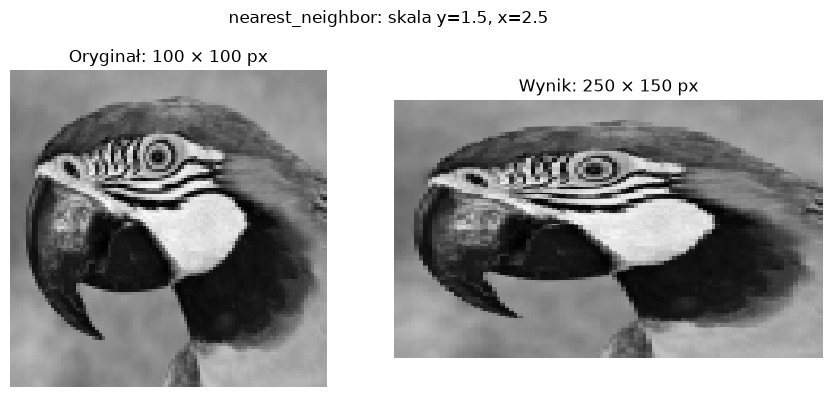

In [6]:
result = nearest_neighbor(parrot, 1.5, 2.5)
show_pair(parrot, result, "nearest_neighbor: skala y=1.5, x=2.5")

#### Papuga: pomniejszenie 0.5 × 0.5

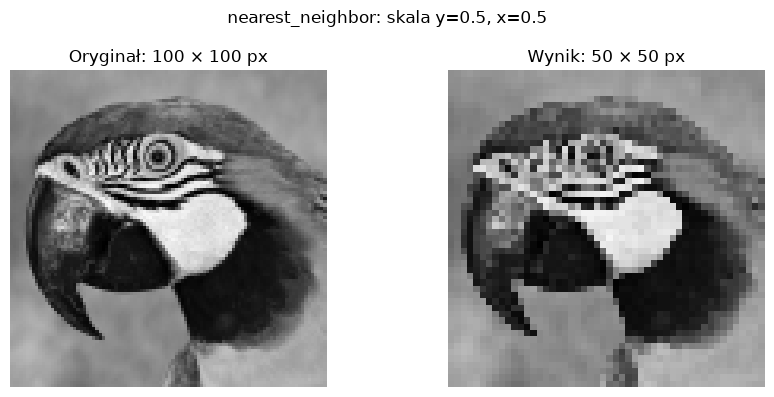

In [7]:
result = nearest_neighbor(parrot, 0.5, 0.5)
show_pair(parrot, result, "nearest_neighbor: skala y=0.5, x=0.5")

#### Zegar: obraz prostokątny

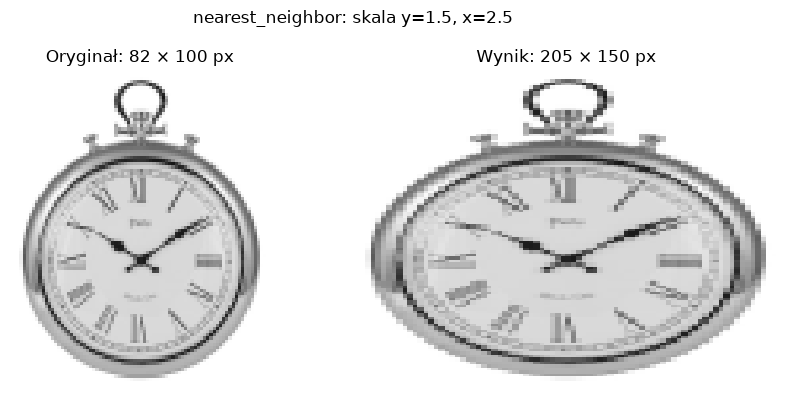

In [8]:
result = nearest_neighbor(clock, 1.5, 2.5)
show_pair(clock, result, "nearest_neighbor: skala y=1.5, x=2.5")

#### Szachownica: powiększenie 2.5 × 2.5

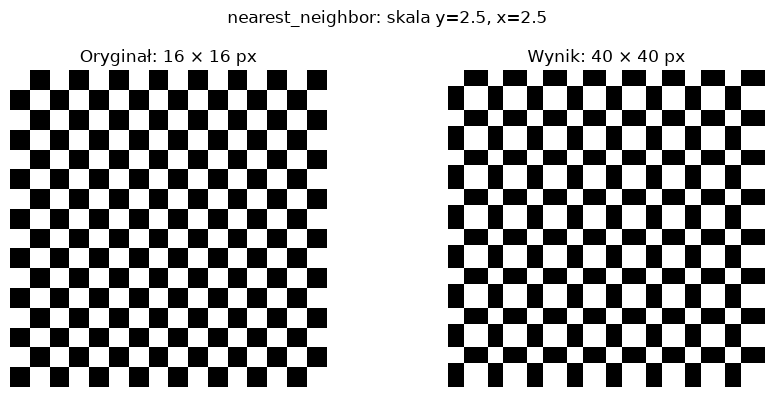

In [9]:
result = nearest_neighbor(chessboard, 2.5, 2.5)
show_pair(chessboard, result, "nearest_neighbor: skala y=2.5, x=2.5")

**Wnioski:** przy powiększaniu widać kwadratowe piksele i schodki na krawędziach.
Metoda nie tworzy nowych poziomów jasności, więc szachownica zachowuje ostre pola.
Różne skale rozciągają proporcje, a pomniejszanie usuwa drobne szczegóły.

## Interpolacja dwuliniowa

W praktyce, lepszym rozwiązaniem zwykle okazuje tzw. **interpolacja dwuliniowa** (ang. *bilinear interpolation*).
Wykorzystuje ona informację o czterech najbliższych sąsiadach do określenia nowej wartości piksela.

Jeśli przez $(i,j)$ oznaczymy współrzędne poszukiwanego piksela, a przez $I(i,j)$ jego jasność (składową w odcieniach szarości) to jego wartość można obliczyć wykorzystując równanie:
\begin{equation}
I(i,j) = a \cdot i + b \cdot j+ c \cdot i \cdot j + d
\end{equation}
gdzie: współczynniki $a,b,c,d$ można wyliczyć na podstawie czterech najbliższych sąsiadów.

![Ilustracja dwuliniowej](https://raw.githubusercontent.com/vision-agh/poc_sw/master/05_Resolution/img/interABCD.png)

Prześledźmy to na przykładzie z powyższego rysunku.
Niech współrzędne poszczególnych punktów to $A = (j_1,i_1)$, $B = (j_1,i_2)$, $ C= (j_2,i_2)$ oraz $D = (j_2,i_1)$.
W pierwszej kolejności dokonujemy interpolacji wartości w punktach $AB$ i $CD$ -- czyli poziomo.
Wychodząc od równania prostej otrzymujemy:

\begin{equation}
f(AB) \approx \frac{i_2 - i}{i_2-i_1}f(A) + \frac{i - i_1}{i_2-i_1}f(B)
\end{equation}

\begin{equation}
f(CD) \approx \frac{i_2 - i}{i_2-i_1}f(D) + \frac{i - i_1}{i_2-i_1}f(C)
\end{equation}

Następnie wykonujemy analogiczną interpolację w pionie:
\begin{equation}
f(ABCD) \approx \frac{j_2 - j}{j_2-j_1}f(AB) + \frac{j - j_1}{j_2-j_1}f(CD)
\end{equation}

Łącząc powyższe równania otrzymujemy:
\begin{equation}
f(ABCD) \approx \frac{1}{(i_2 - i_1)(j_2-j_1)} ( f(A)(i_2-i)(j_2 - y) + f(B)(i-i_1)(j_2 - j) \\ + f(C)(i-i_1)(j-j_1) + f(D)(i_2-i)(j-j_1))
\end{equation}
gdzie zapis $f(X)$ oznacza wartość piksela w punkcie $X$.

Rozważania można uprościć przyjmując, że narożniki rozpatrywanego kwadratu mają następujące współrzędne: $A = (0,0)$, $B = (0,1)$, $ C= (1,1)$ oraz $D = (1,0)$.
Wtedy powyższe równanie można zapisać:
\begin{equation}
f(ABCD) \approx f(A)(1-i)(1-j) + f(B)i(1-j) + f(C)ij + f(D)(1-i)j
\end{equation}

lub macierzowo:
\begin{equation}
f(ABCD) \approx \begin{bmatrix}1 - i & i \end{bmatrix} \begin{bmatrix} f(A) & f(D) \\\\ f(B) & f(C)  \end{bmatrix}   \begin{bmatrix} 1-j \\\\ j  \end{bmatrix}
\end{equation}

Uwaga.
Nieco wbrew nazwie interpolacja dwuliniowa nie jest operacją liniową.
W złożeniu dwóch operacji liniowych pojawia się człon $xy$.

Warto dodać, że kolejny ``poziom wtajemniczenia'' to **interpolacja dwusześcienna** (ang. *bicubic interpolation*).
Dana jest ona wzorem:
\begin{equation}
I(i,j) = \sum_{i=0}^{3} \sum_{j=0}^{3} a_{ij} x^i y^j
\end{equation}
Jej implementacja stanowi zadanie domowe do bieżącego ćwiczenia.

Trzy powyżej przedstawione metody bynajmniej nie wyczerpują tematu.
Wystarczy choćby otworzyć stronę [wiki o skalowaniu](https://en.wikipedia.org/wiki/Image_scaling), by zobaczyć, że metod jest dużo więcej.



Wykorzystując powyższe równania zaimplementuj interpolację dwuliniową:
* dobrym punktem wyjścia będzie stworzona funkcja do interpolacji metodą najbliższego sąsiada,
* początek powinien być identyczny,
* różnice rozpoczynają się w momencie obliczenia współrzędnych nowego piksela,
* jeśli chcemy zastosować opisane powyżej wzory (w wariancie uproszczonym), to musimy wyliczyć współrzędne punktów $A,B,C,D$,
* w pierwszym kroku obliczamy współrzędne $A$ tj. $(0,0)$ - należy do tego wykorzystać funkcję *floor* (np. $i_1 = floor(i / h_{scale})$).
  Proszę ten krok odnieść do przedstawionego rysunku poglądowego,
* obliczenie współrzędnych $B,C,D$ jest już proste i sprowadza się do operacji `+1`,
* potrzebujemy jeszcze część ułamkową współrzędnych punktu $ABCD$ tj. $(i,j)$ - od ilorazu $i/h_{scale}$ należy odjąć wartość $i_1$
* wykorzystując wyznaczone współrzędne, należy pobrać wartości jasności w punktach $A,B,C,D$, tj. $f(A),f(B),f(C),f(D)$, podstawić do odpowiedniego równania i wykonać interpolację.

  Uwagi:
* Tworzenie macierzy *np.array*, mnożenie macierzy *np.dot*. Przy tworzeniu macierzy proszę zwrócić uwagę na niezbędne nawiasy kwadratowe.
* Przy próbie uruchomienia kodu pewnie okaże się, że wystąpi przekroczenie zakresu - należy dodać stosowne zabezpiczenie.

Proszę dla interpolacji dwuliniowej wykonać takie same eksperymenty, jak dla  najbliższego sąsiada.




In [ ]:
def bilinear(image, h_scale, w_scale):
    height, width = image.shape
    
    new_height = max(1, round(height * h_scale))
    new_width = max(1, round(width * w_scale))
    result = np.zeros((new_height, new_width), dtype=image.dtype)

    sy = new_height / height
    sx = new_width / width
    
    for y in range(new_height):
        for x in range(new_width):
            src_y = (y + 0.5) / sy - 0.5
            src_x = (x + 0.5) / sx - 0.5
            src_y = min(max(src_y, 0), height - 1)
            src_x = min(max(src_x, 0), width - 1)

            y0 = int(np.floor(src_y))
            x0 = int(np.floor(src_x))
            y1 = min(y0 + 1, height - 1)
            x1 = min(x0 + 1, width - 1)
            dy = src_y - y0
            dx = src_x - x0

            # A, B: górny wiersz; D, C: dolny wiersz.
            A = float(image[y0, x0])
            B = float(image[y0, x1])
            C = float(image[y1, x1])
            D = float(image[y1, x0])
            value = (A * (1 - dx) * (1 - dy) + B * dx * (1 - dy)
                     + C * dx * dy + D * (1 - dx) * dy)
            result[y, x] = round(value)
    
    return result

`floor` wskazuje lewy górny narożnik sąsiedztwa. `dx` i `dy` to części ułamkowe:
mówią, jak daleko punkt leży od tego narożnika. Cztery wagi sumują się do 1.
Wynik jest średnią ważoną czterech pikseli. Przy brzegu powtarzamy skrajny piksel.
Używamy tego samego przeliczenia środków pikseli co w pierwszej metodzie.

#### Papuga: powiększenie 1.5 × 1.5

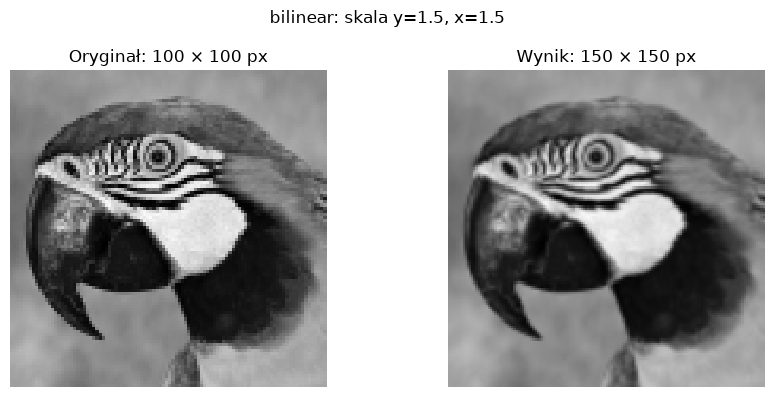

In [11]:
result = bilinear(parrot, 1.5, 1.5)
show_pair(parrot, result, "bilinear: skala y=1.5, x=1.5")

#### Papuga: powiększenie 2.5 × 2.5

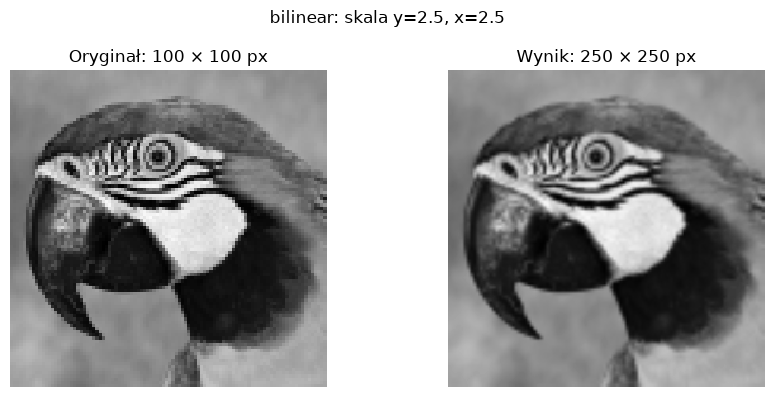

In [12]:
result = bilinear(parrot, 2.5, 2.5)
show_pair(parrot, result, "bilinear: skala y=2.5, x=2.5")

#### Papuga: różne skale w pionie i poziomie

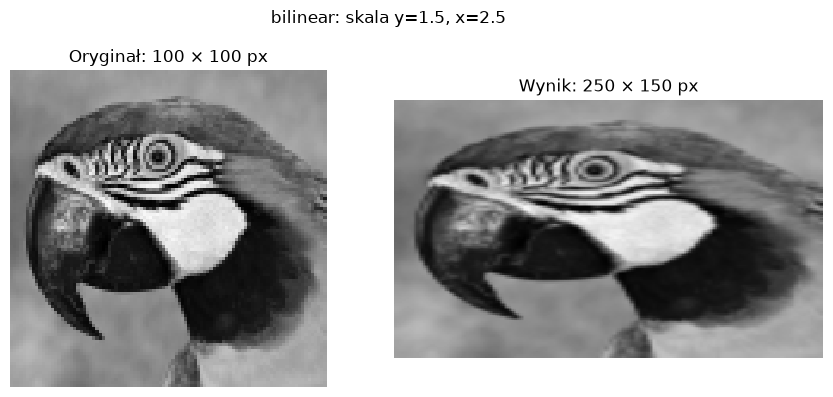

In [13]:
result = bilinear(parrot, 1.5, 2.5)
show_pair(parrot, result, "bilinear: skala y=1.5, x=2.5")

#### Papuga: pomniejszenie 0.5 × 0.5

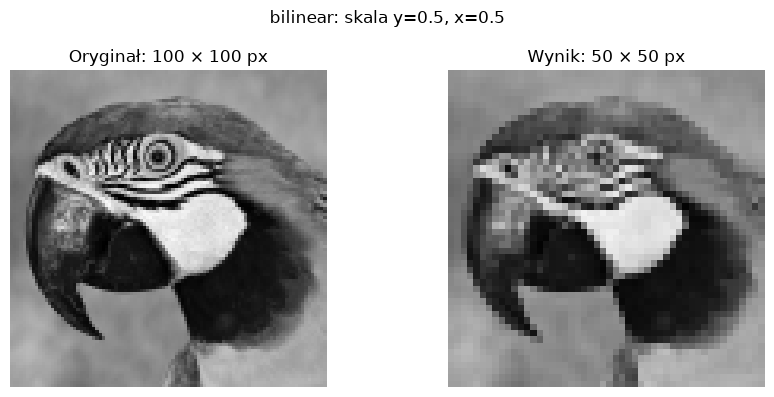

In [14]:
result = bilinear(parrot, 0.5, 0.5)
show_pair(parrot, result, "bilinear: skala y=0.5, x=0.5")

#### Zegar: obraz prostokątny

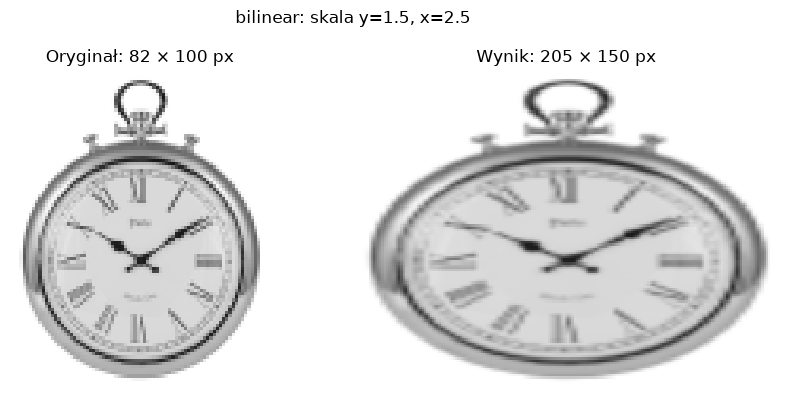

In [15]:
result = bilinear(clock, 1.5, 2.5)
show_pair(clock, result, "bilinear: skala y=1.5, x=2.5")

#### Szachownica: powiększenie 2.5 × 2.5

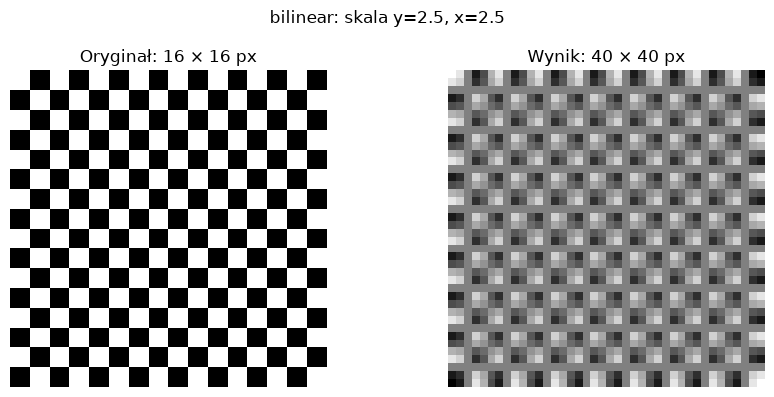

In [16]:
result = bilinear(chessboard, 2.5, 2.5)
show_pair(chessboard, result, "bilinear: skala y=2.5, x=2.5")

**Wnioski:** interpolacja dwuliniowa wygładza krawędzie i zmniejsza widoczność schodków,
ale rozmywa drobne szczegóły. Na granicach pól szachownicy pojawiają się szarości.
Przy pomniejszaniu obie ręczne metody mogą powodować aliasing (fałszywe wzory),
ponieważ nie uśredniają całego obszaru przypadającego na nowy piksel.

## Intepolacja w OpenCV

W OpenCV dostępna jest funkcja `resize`, która służy do zmiany rozmiaru obrazka.
Składnia jest następująca `dst = cv2.resize(src, dsize[, dst[, fx[, fy[, interpolation]]]] )`, gdzie `dst` to obraz wynikowy, `src` obraz źródłowy, `dsize` rozmiar docelowy (ew. można podać współczynniki skalowania dla poszczególnych osi: `fx,fy`), `interpolation` metoda interpolacji.
Metod podstawowych dostępnych jest 5:
- najbliższego sąsiada - ` cv2.INTER_NEAREST`,
- dwuliniowa - ` cv2.INTER_LINEAR`,
- dwukubiczna - ` cv2.INTER_CUBIC`,
- *area* - ` cv2.INTER_AREA`,
- *lanczos4* - ` cv2.INTER_LANCZOS4`.

Przeprowadzimy następujący eksperyment: obraz (o większej niż dotąd rozdzielczości) przeskalujemy każdą z metod -- zwiększymy i zmniejszymy jego rozdzielczość. Dodamy też pomiar czasu realizacji obliczeń.

Proszę stworzyć funkcję, która jako argumenty przyjmuje obraz oraz dwa współczynniki skalujące, a wewnątrz przeprowadzone zostaną interpolacje, pomiar czasu oraz wizualizacja (można wypisać czas w tytule rysunku).

Pomiar czasu:
```{python}
from timeit import default_timer as timer
start = timer()
# ...
end = timer()
print(end - start)
```

Wykonaj eksperyment dla kilku różnych skal, przeanalizuj czasy obliczeń.

In [ ]:
from timeit import default_timer as timer

firetruck = cv2.imread(str(folder / "firetruck.jpg"))
firetruck = cv2.cvtColor(firetruck, cv2.COLOR_BGR2RGB)

def compare_opencv(image, h_scale, w_scale):
    methods = [("NEAREST", cv2.INTER_NEAREST),
               ("LINEAR", cv2.INTER_LINEAR),
               ("CUBIC", cv2.INTER_CUBIC),
               ("AREA", cv2.INTER_AREA),
               ("LANCZOS4", cv2.INTER_LANCZOS4)]
    
    size = (round(image.shape[1] * w_scale), round(image.shape[0] * h_scale))
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.ravel()
    axes[0].imshow(image, interpolation="nearest")
    axes[0].set_title(f"Oryginał: {image.shape[1]} × {image.shape[0]} px")
    times = {}
    
    for ax, (name, method) in zip(axes[1:], methods):
        cv2.resize(image, size, interpolation=method)  # rozgrzewka
        start = timer()
        
        for _ in range(5):
            result = cv2.resize(image, size, interpolation=method)
        elapsed_ms = (timer() - start) / 5 * 1000
        times[name] = elapsed_ms
        
        ax.imshow(result, interpolation="nearest")
        ax.set_title(f"{name}: {elapsed_ms:.3f} ms")
        print(f"{name:8s}: {elapsed_ms:.3f} ms")
    
    for ax in axes:
        ax.axis("off")
    
    fig.suptitle(f"OpenCV: skala y={h_scale}, x={w_scale}; wynik {size[0]} × {size[1]} px")
    plt.tight_layout()
    plt.show()
    
    return times

NEAREST : 0.204 ms
LINEAR  : 0.279 ms
CUBIC   : 0.621 ms
AREA    : 0.286 ms
LANCZOS4: 1.657 ms


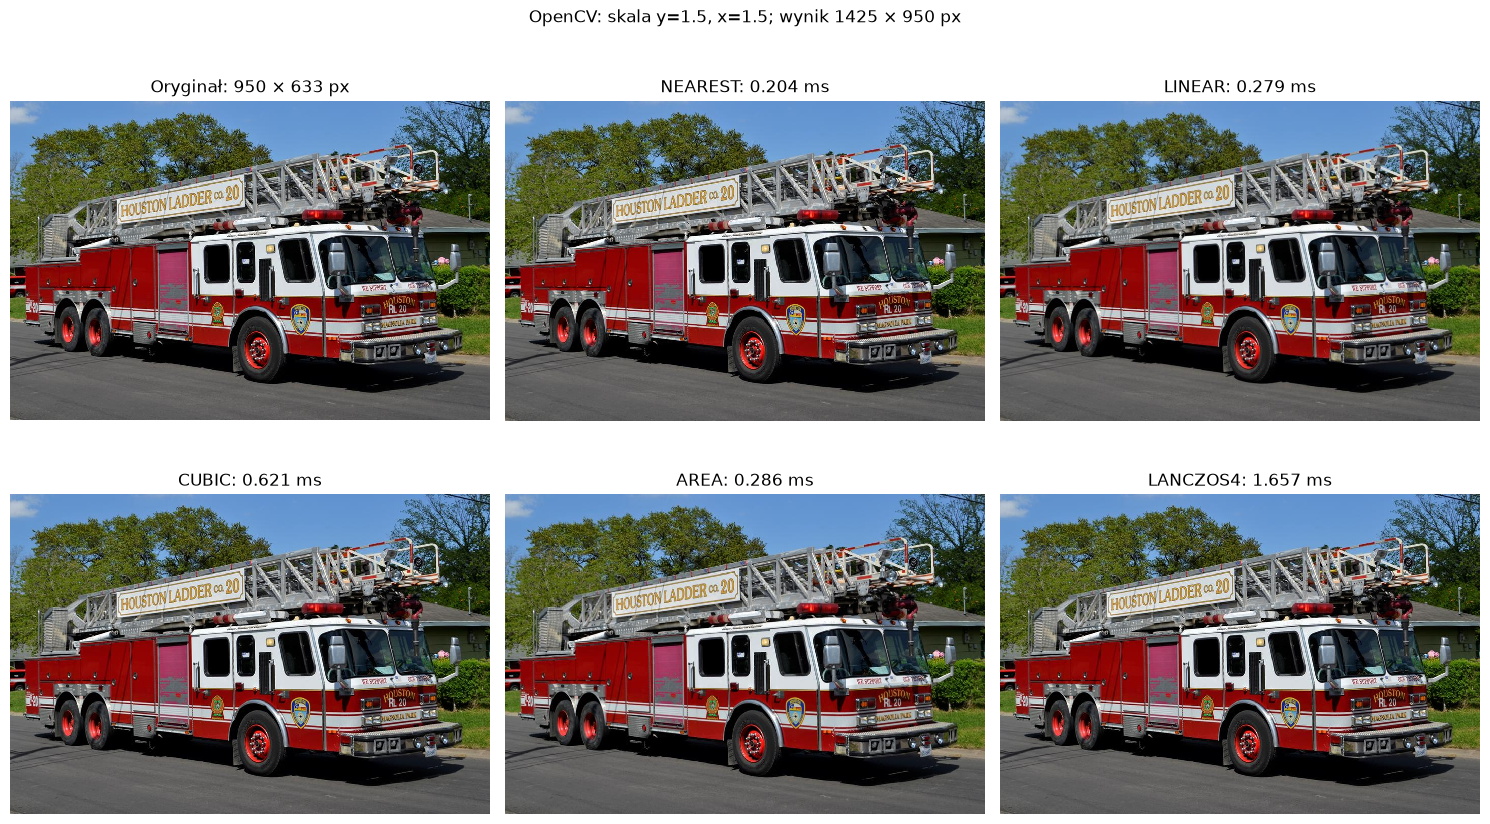

In [18]:
times_up = compare_opencv(firetruck, 1.5, 1.5)

NEAREST : 0.063 ms
LINEAR  : 0.056 ms
CUBIC   : 0.475 ms
AREA    : 0.937 ms
LANCZOS4: 1.106 ms


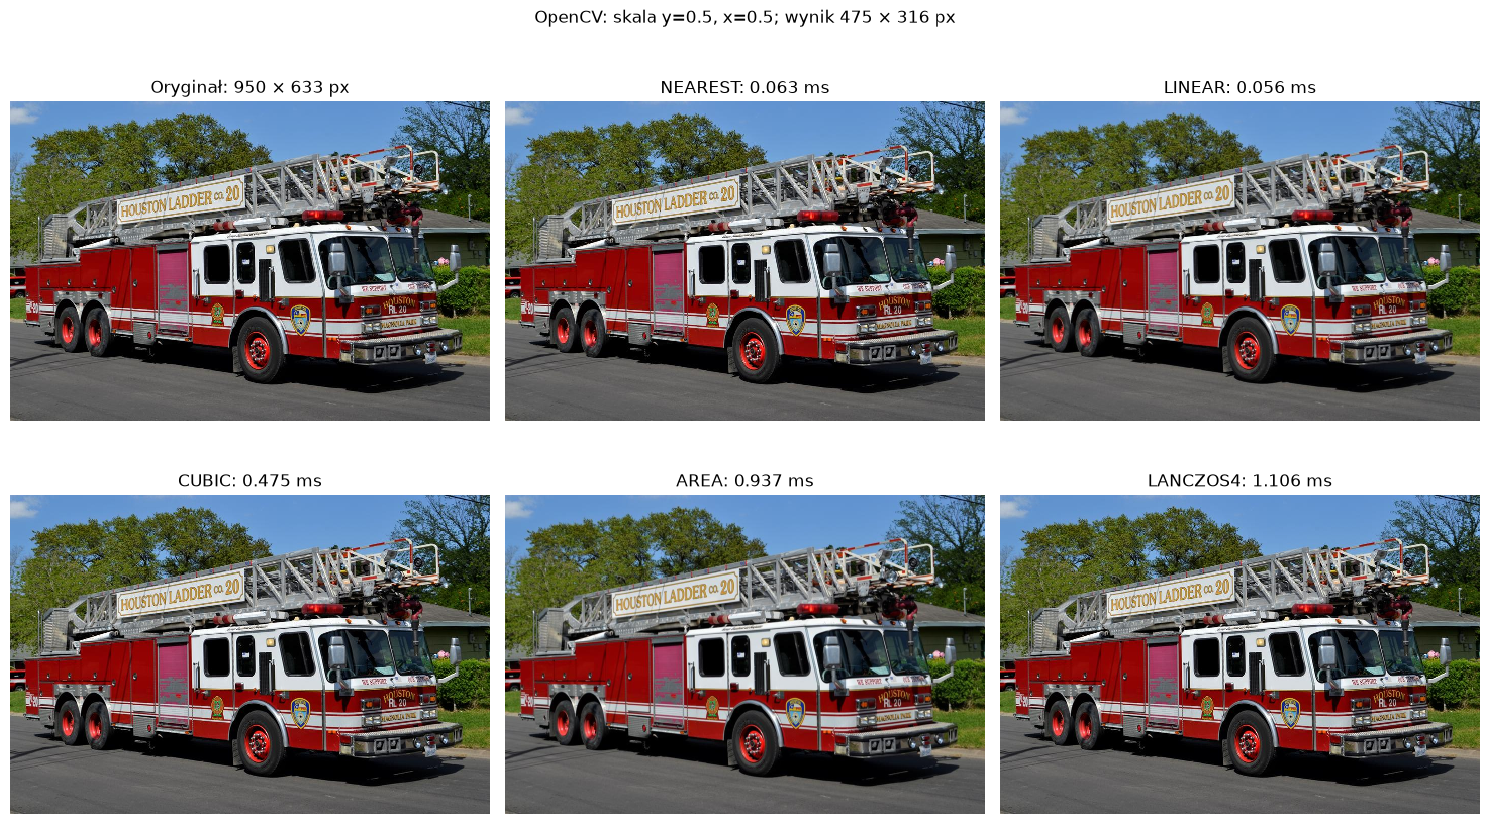

In [19]:
times_down = compare_opencv(firetruck, 0.5, 0.5)

NEAREST : 0.123 ms
LINEAR  : 0.251 ms
CUBIC   : 0.633 ms
AREA    : 0.254 ms
LANCZOS4: 1.441 ms


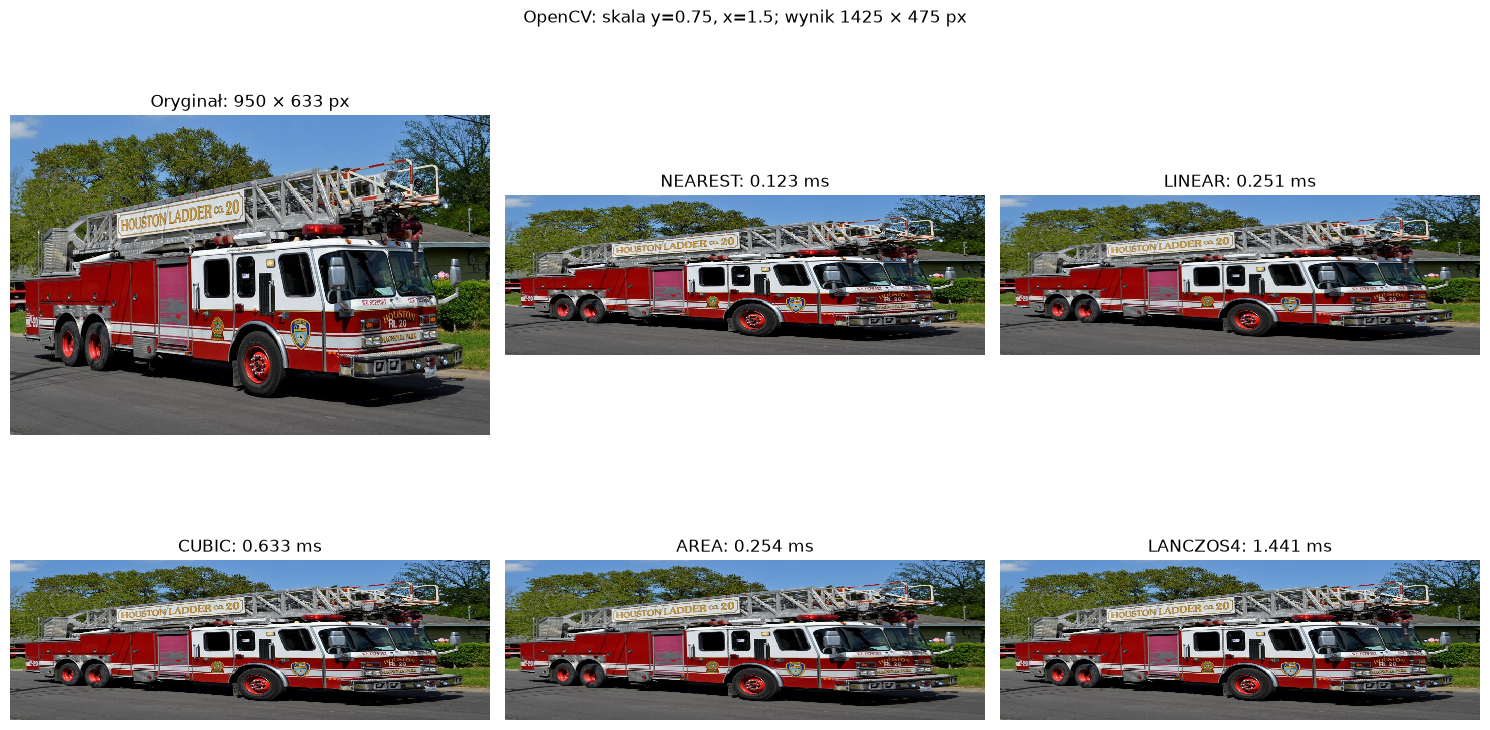

In [20]:
times_unequal = compare_opencv(firetruck, 0.75, 1.5)

**Wnioski:** NEAREST daje ostre, schodkowe krawędzie; LINEAR wygładza, a CUBIC
i LANCZOS4 zwykle lepiej zachowują szczegóły, ale mogą tworzyć obwódki przy krawędziach.
AREA uśrednia obszary i jest dobrym wyborem do pomniejszania.

W tym uruchomieniu najszybsze były NEAREST lub LINEAR, a najwolniejszy był LANCZOS4.
CUBIC i LANCZOS4 korzystają z większego sąsiedztwa, więc wykonują więcej obliczeń.
Powiększenie zwykle trwało dłużej niż pomniejszenie, ponieważ trzeba wyznaczyć więcej pikseli.
AREA przy pomniejszaniu był wolniejszy od LINEAR — uśrednianie obszarów też ma swój koszt.

## Rozdzielczość (dpi)

Omówioną wcześniej rozdzielczość przestrzenną (rozmiar) należy utożsamiać z rozmiarem macierzy w której zapisany jest obraz.
W tym ujęciu rozmiar pojedynczego piksela nie ma specjalnego znaczenia.
Problem pojawia się, kiedy obraz trzeba wyświetlić lub wydrukować.
Wtedy pojedynczy piksel staje się ,,obiektem fizycznym'' i musi mieć swój rozmiar (wysokość/szerokość/powierzchnię).

Parametr dpi (ang. *dots per inch*) określa liczbę kropek (pikseli), która mieści się na jednym calu (25,4 mm) długości/szerokości.
Dopiero kombinacja rozmiaru i rozdzielczości określa nam rzeczywisty rozmiar obrazu jaki uzyskamy na wydruku.

Dpi staje się istotne w przypadku drukowania, gdyż wyświetlanie na monitorze odbywa się zazwyczaj 1 piksel obrazka = 1 piksel na monitorze (w przypadku maksymalnej rozdzielczości wspieranej przez monitor), ew. następuje automatyczne skalowanie.

Wpływ rozdzielczości można zademonstrować w następujący sposób:
- wczytaj obraz *lena.bmp*.  Ma on rozmiar $512 \times 512$.
- wykorzystując funkcję `imresize` stwórz obrazy o rozmiarach $256 \times 256$, $128 \times 128$, $64 \times 64$ - metoda interpolacji jest w tym wypadku mniej istotna.
- wyświetl obrazy wymuszając zachowanie na ekranie wejściowej rozdzielczości $512 \times 512$. W przypadku biblioteki *matplotlib* ta funkcjonalność jest domyślna.

Proszę zaobserwować co dzieje się z obrazkiem.

Rozmiar oryginału: (512, 512)


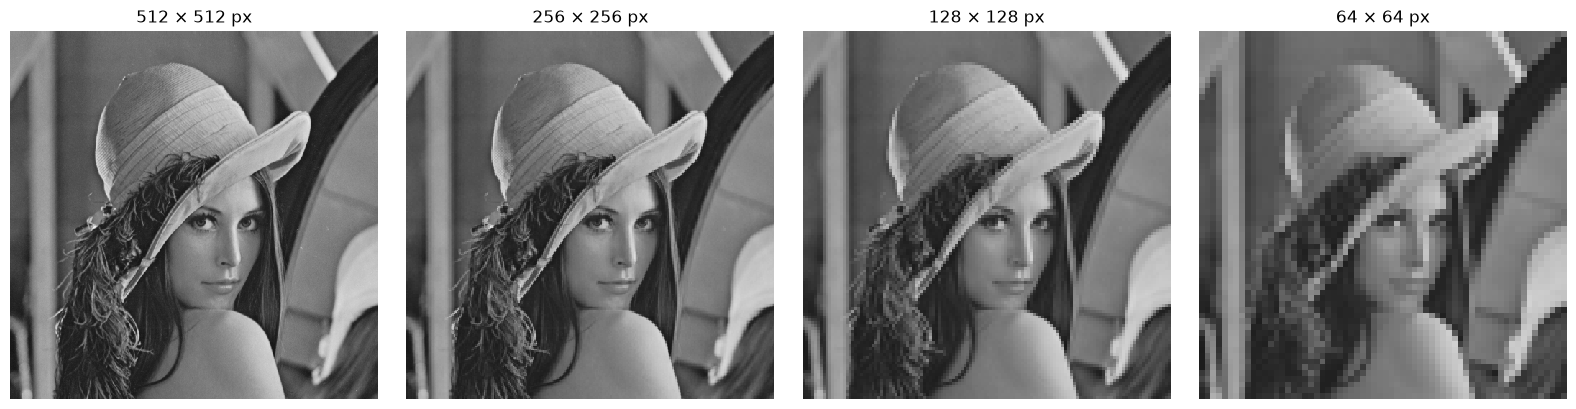

In [ ]:
lena = cv2.imread(str(folder / "lena.bmp"), cv2.IMREAD_GRAYSCALE)
print("Rozmiar oryginału:", lena.shape)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, size in zip(axes, [512, 256, 128, 64]):
    small = cv2.resize(lena, (size, size), interpolation=cv2.INTER_AREA)
    # każdy obraz zajmuje takie samo miejsce na wykresie (obszar 512 × 512).
    ax.imshow(small, cmap="gray", vmin=0, vmax=255,
              interpolation="nearest", extent=(0, 512, 512, 0))
    ax.set_title(f"{size} × {size} px")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Obserwacja:** wszystkie obrazy mają taki sam rozmiar na wykresie, ale wersje 128 × 128
i 64 × 64 mają mniej szczegółów i większe widoczne piksele.
Powiększenie sposobu wyświetlania nie przywraca utraconej informacji.
Fizyczny rozmiar wydruku liczymy jako `liczba pikseli / dpi` w calach.
Dla 512 pikseli: przy 100 dpi jest to 5.12 cala, a przy 200 dpi — 2.56 cala.

## Liczba poziomów jasności

Dla obrazów w skali szarości pojedynczy piksel zwykle zapisuje się na 8 bitach, co daje 256 rozróżnialnych poziomów szarości.
Dla większości zastosowań wartość ta jest wystarczająca (choć są kamery o wyjścu 12 lub 16 bitów).
Jednak oko ludzkie nie potrafi rozróżnić wszystkich 256 poziomów jasności (jest za mało czułe).
Zazwyczaj człowiek rozróżnia 20-30 poziomów szarości (to ile i jakie dokładnie rozróżnia, zależy od konkretnego oświetlenia sceny i cech osobniczych).

W poniższych krokach zademonstrujemy omówione zjawisko:
- wczytaj (użyj) obrazu _lena_,
- wykorzystując znaną funkcję `normalize` zmień liczbę poziomów szarości z 0-255 na:
    * 0-31
    * 0-15
    * 0-7
    * 0-3
    * 0-1 (binaryzacja)
- rezultaty wyświetl na wspólnym rysunku.

Podpowiedzi:
- trzeba przygotować tablice na obrazki np, `I_31 = np.zeros(I.shape,'uint8')`,
- prawidłowe użycie funkcji normalize `cv2.normalize(I,I_31,0,31,cv2.NORM_MINMAX)`,
- przykładowe wyświetlanie `axsHist[0,1].imshow(I, 'gray', vmin=0, vmax=31)`.

Czy rezultaty eksperymentu pasują do teorii o rozpoznawaniu przez człowieka ograniczonego zakresu poziomów jasności?
Wizualne porównanie których obrazów o tym świadczy?

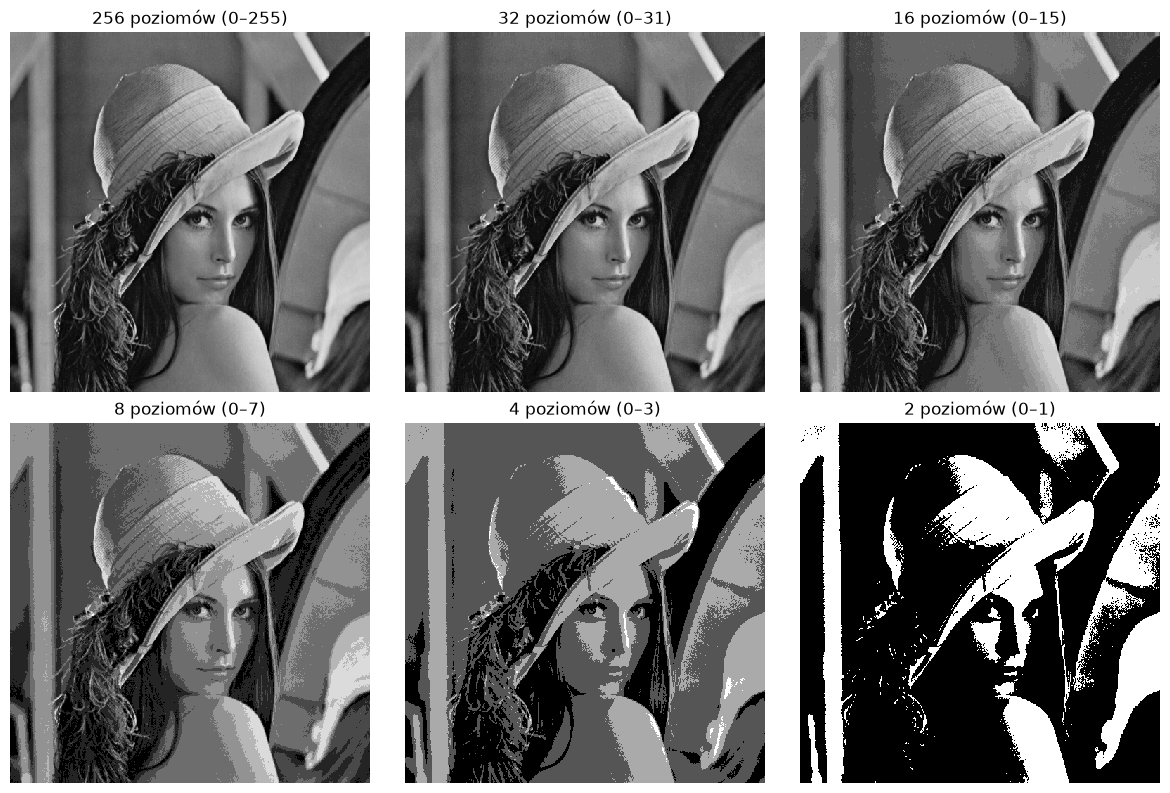

In [ ]:
quantized_images = {}
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, levels in zip(axes.ravel(), [256, 32, 16, 8, 4, 2]):
    quantized = np.zeros_like(lena)
    cv2.normalize(lena, quantized, 0, levels - 1, cv2.NORM_MINMAX)
    quantized_images[levels] = quantized

    ax.imshow(quantized, cmap="gray", vmin=0, vmax=levels - 1,
              interpolation="nearest")
    ax.set_title(f"{levels} poziomów (0–{levels - 1})")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Odpowiedź:** porównanie 256 i 32 poziomów pokazuje, że można mocno ograniczyć
liczbę jasności i nadal zachować podobny wygląd obrazu. Przy 16, a zwłaszcza 8 poziomach
coraz bardziej widać pasy zamiast płynnych przejść (posteryzację).
Przy 4 i 2 poziomach ginie wiele szczegółów.

Wynik jest zgodny z ogólną obserwacją, że nie zawsze dostrzegamy wszystkie 256 poziomów.